In [1]:
import zipfile
import os

zip_path = '/content/archive (3).zip'
extract_dir = '/content/extracted_data'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

print("Extracted files:")
for root, dirs, files in os.walk(extract_dir):
    for file in files:
        print(os.path.join(root, file))

Extracted files:
/content/extracted_data/Skin_Data/Non_Cancer/Testing/108-1.JPG
/content/extracted_data/Skin_Data/Non_Cancer/Testing/738-4.JPG
/content/extracted_data/Skin_Data/Non_Cancer/Testing/911-2.JPG
/content/extracted_data/Skin_Data/Non_Cancer/Testing/807-01.JPG
/content/extracted_data/Skin_Data/Non_Cancer/Testing/1500-2.JPG
/content/extracted_data/Skin_Data/Non_Cancer/Testing/1364.JPG
/content/extracted_data/Skin_Data/Non_Cancer/Testing/191-02.JPG
/content/extracted_data/Skin_Data/Non_Cancer/Testing/1383-02.JPG
/content/extracted_data/Skin_Data/Non_Cancer/Testing/2053-3.JPG
/content/extracted_data/Skin_Data/Non_Cancer/Testing/2040-1.JPG
/content/extracted_data/Skin_Data/Non_Cancer/Testing/1045-2.JPG
/content/extracted_data/Skin_Data/Non_Cancer/Testing/1127-1.JPG
/content/extracted_data/Skin_Data/Non_Cancer/Testing/1150-01.JPG
/content/extracted_data/Skin_Data/Non_Cancer/Testing/281.JPG
/content/extracted_data/Skin_Data/Non_Cancer/Testing/2047-02.JPG
/content/extracted_data/Skin

In [5]:
import os
import glob
import pandas as pd

# Search for JPG and jpg images recursively
image_paths = glob.glob(os.path.join(extract_dir, '**/*.JPG'), recursive=True) + \
              glob.glob(os.path.join(extract_dir, '**/*.jpg'), recursive=True)

data_list = []
for path in image_paths:
    parts = path.split(os.sep)
    try:
        # Format is /content/extracted_data/Skin_Data/{Label}/{Partition}/{Filename}
        label = parts[-3]
        partition = parts[-2]
        data_list.append({
            'file_path': path,
            'label': label,
            'original_partition': partition
        })
    except IndexError:
        continue

df = pd.DataFrame(data_list)
print(f"Total images mapped: {len(df)}")
display(df.head())

Total images mapped: 288


,file_path,label,original_partition
0,/content/extracted_data/Skin_Data/Non_Cancer/T...,Non_Cancer,Testing
1,/content/extracted_data/Skin_Data/Non_Cancer/T...,Non_Cancer,Testing
2,/content/extracted_data/Skin_Data/Non_Cancer/T...,Non_Cancer,Testing
3,/content/extracted_data/Skin_Data/Non_Cancer/T...,Non_Cancer,Testing
4,/content/extracted_data/Skin_Data/Non_Cancer/T...,Non_Cancer,Testing


--- Overall Class Distribution ---
label
Non_Cancer    204
Cancer         84
Name: count, dtype: int64

--- Original Folder Split ---
original_partition
Testing     204
Training     84
Name: count, dtype: int64


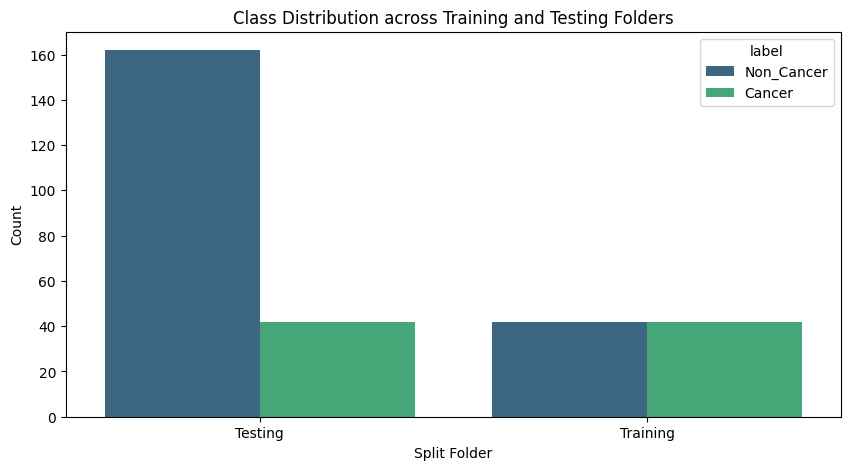

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Perform EDA
if not df.empty:
    print("--- Overall Class Distribution ---")
    print(df['label'].value_counts())

    print("\n--- Original Folder Split ---")
    print(df['original_partition'].value_counts())

    # Visualize the distributions
    plt.figure(figsize=(10, 5))
    sns.countplot(data=df, x='original_partition', hue='label', palette='viridis')
    plt.title('Class Distribution across Training and Testing Folders')
    plt.xlabel('Split Folder')
    plt.ylabel('Count')
    plt.show()
else:
    print("No image metadata available.")

In [7]:
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split

# Separate data into train and test according to directory structure
train_df = df[df['original_partition'].str.lower() == 'training'].copy()
test_df = df[df['original_partition'].str.lower() == 'testing'].copy()

# If folders were not distinct, perform standard stratified splitting
if train_df.empty or test_df.empty:
    train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['label'])

# Split training further to obtain a validation set (15% of training)
train_df, val_df = train_test_split(train_df, test_size=0.15, random_state=42, stratify=train_df['label'])

print(f"Train samples: {len(train_df)}")
print(f"Validation samples: {len(val_df)}")
print(f"Test samples: {len(test_df)}")

# Set image size and generators
img_size = (128, 128)
batch_size = 32

datagen = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1./255)

train_gen = datagen.flow_from_dataframe(
    train_df, x_col='file_path', y_col='label', target_size=img_size,
    batch_size=batch_size, class_mode='binary'
)

val_gen = datagen.flow_from_dataframe(
    val_df, x_col='file_path', y_col='label', target_size=img_size,
    batch_size=batch_size, class_mode='binary'
)

test_gen = datagen.flow_from_dataframe(
    test_df, x_col='file_path', y_col='label', target_size=img_size,
    batch_size=batch_size, class_mode='binary', shuffle=False
)

# Build CNN Architecture
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(128, 128, 3)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

# Train the model
history = model.fit(
    train_gen,
    epochs=5,
    validation_data=val_gen
)

# Evaluate accuracy on test dataset
loss, acc = model.evaluate(test_gen)
print(f"Test Accuracy: {acc:.4f}")

Train samples: 71
Validation samples: 13
Test samples: 204
Found 71 validated image filenames belonging to 2 classes.
Found 13 validated image filenames belonging to 2 classes.
Found 204 validated image filenames belonging to 2 classes.


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 836ms/step - accuracy: 0.3944 - loss: 0.7193 - val_accuracy: 0.5385 - val_loss: 0.7052
Epoch 2/5
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 1s/step - accuracy: 0.4930 - loss: 0.7200 - val_accuracy: 0.5385 - val_loss: 0.6853
Epoch 3/5
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 734ms/step - accuracy: 0.5915 - loss: 0.6859 - val_accuracy: 0.6154 - val_loss: 0.6858
Epoch 4/5
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 724ms/step - accuracy: 0.6197 - loss: 0.6791 - val_accuracy: 0.6154 - val_loss: 0.6705
Epoch 5/5
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 2s/step - accuracy: 0.6761 - loss: 0.6588 - val_accuracy: 0.5385 - val_loss: 0.6528
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 271ms/step - accuracy: 0.3039 - loss: 0.7332
Test Accuracy: 0.3039


In [10]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

# Get predictions on the test dataset
predictions = model.predict(test_gen)
predicted_classes = (predictions > 0.5).astype(int).ravel()

# Retrieve true labels and class mappings using the correct attribute 'class_indices'
true_classes = test_gen.classes
class_labels = list(test_gen.class_indices.keys())

# Calculate and print test accuracy and detailed report
loss, accuracy = model.evaluate(test_gen, verbose=0)
print(f"Test Accuracy: {accuracy * 100:.2f}%")
print("\n--- Classification Report ---")
print(classification_report(true_classes, predicted_classes, target_names=class_labels))

7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 269ms/step
Test Accuracy: 30.39%

--- Classification Report ---
              precision    recall  f1-score   support

      Cancer       0.23      1.00      0.37        42
  Non_Cancer       1.00      0.12      0.22       162

    accuracy                           0.30       204
   macro avg       0.61      0.56      0.30       204
weighted avg       0.84      0.30      0.25       204



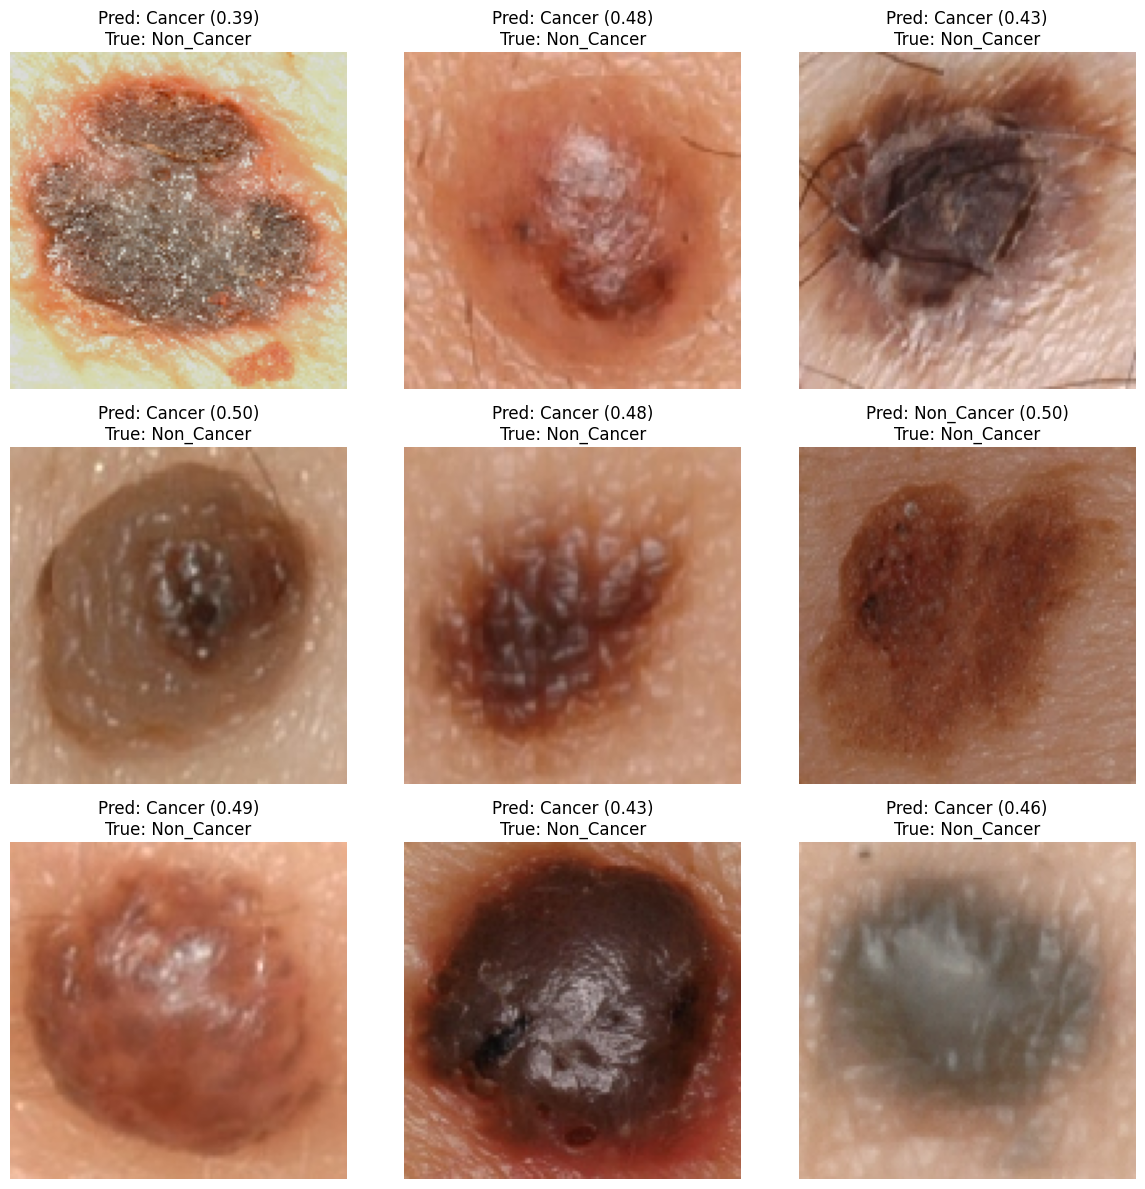

In [11]:
# Map back indices to labels for visual demonstration using 'class_indices'
inv_map = {v: k for k, v in test_gen.class_indices.items()}

# Plot sample predictions from the test generator
plt.figure(figsize=(12, 12))
test_gen.reset()
x_batch, y_batch = next(test_gen)

for i in range(min(9, len(x_batch))):
    plt.subplot(3, 3, i + 1)
    plt.imshow(x_batch[i])

    # Make prediction on single image
    pred_prob = model.predict(np.expand_dims(x_batch[i], axis=0), verbose=0)[0][0]
    pred_label = inv_map[int(pred_prob > 0.5)]
    true_label = inv_map[int(y_batch[i])]

    plt.title(f"Pred: {pred_label} ({pred_prob:.2f})\nTrue: {true_label}")
    plt.axis('off')
plt.tight_layout()
plt.show()

In [12]:
import numpy as np
import pandas as pd

# Take exactly 100 sample images from the test set (or entire df if preferred)
sample_df = test_df.sample(n=min(100, len(test_df)), random_state=42).copy()

# Create a quick generator for these 100 samples
sample_gen = datagen.flow_from_dataframe(
    sample_df, x_col='file_path', y_col='label', target_size=img_size,
    batch_size=1, class_mode='binary', shuffle=False
)

# Predict classes
probs = model.predict(sample_gen, steps=len(sample_gen))
preds = (probs > 0.5).astype(int).ravel()

# Map predictions back to labels
inv_map = {v: k for k, v in sample_gen.class_indices.items()}
sample_df['Predicted_Label'] = [inv_map[p] for p in preds]
sample_df['Probability_Cancer'] = 1.0 - probs.ravel()  # Since binary maps Non_Cancer to 1 and Cancer to 0, or vice versa depending on class indices

# Show the results
pd.set_option('display.max_rows', 100)
display(sample_df[['file_path', 'label', 'Predicted_Label', 'Probability_Cancer']].head(100))

Found 100 validated image filenames belonging to 2 classes.
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step


,file_path,label,Predicted_Label,Probability_Cancer
15,/content/extracted_data/Skin_Data/Non_Cancer/T...,Non_Cancer,Cancer,0.524170
9,/content/extracted_data/Skin_Data/Non_Cancer/T...,Non_Cancer,Non_Cancer,0.494885
115,/content/extracted_data/Skin_Data/Non_Cancer/T...,Non_Cancer,Cancer,0.528122
78,/content/extracted_data/Skin_Data/Non_Cancer/T...,Non_Cancer,Cancer,0.577520
66,/content/extracted_data/Skin_Data/Non_Cancer/T...,Non_Cancer,Cancer,0.512081
45,/content/extracted_data/Skin_Data/Non_Cancer/T...,Non_Cancer,Cancer,0.523452
132,/content/extracted_data/Skin_Data/Non_Cancer/T...,Non_Cancer,Cancer,0.558923
203,/content/extracted_data/Skin_Data/Cancer/Testi...,Cancer,Cancer,0.555348
278,/content/extracted_data/Skin_Data/Non_Cancer/T...,Non_Cancer,Cancer,0.546250
223,/content/extracted_data/Skin_Data/Cancer/Testi...,Cancer,Cancer,0.574348


In [13]:
model.save('skin_cancer_detector_model.keras')
print("Model saved successfully as 'skin_cancer_detector_model.keras'.")

Model saved successfully as 'skin_cancer_detector_model.keras'.
